# 02 — Clima, canal endémico y tabla de modelado (Ibagué)

Toma la serie mensual de casos del notebook 01 y el clima diario de Google Earth Engine y construye los niveles 2 y 3 del documento *Estructura de datos para los modelos*:

- **Nivel 2** (`serie_nivel2_73001.csv`): una fila por mes con casos, clima, ONI, umbral del canal endémico y `exceso`.
- **Nivel 3** (`tabla_modelado_73001.csv`): una fila por ejemplo de entrenamiento: ventana de 4 meses (t-5 a t-2) + objetivo en t.

**Entradas**
- `Datos/dengue/procesado/serie_mensual_municipios.csv` (sale del notebook 01).
- `Datos/clima/GEE_Clima_Ibague/*.csv` (clima diario con columnas `fecha, temp_media_c, temp_min_c, temp_max_c, precipitacion_mm`).
- Opcional: `Datos/poblacion_ibague.csv` con columnas `anio, poblacion` (proyecciones DANE). Si no existe, se trabaja con conteos.

**Salidas:** `Datos/dengue/procesado/serie_nivel2_73001.csv` y `Datos/dengue/procesado/tabla_modelado_73001.csv`

## 1. Configuración
Las decisiones metodológicas quedan como parámetros, para poder cambiarlas y justificar cada una en el informe.

In [ ]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

BASE      = '/content/drive/MyDrive/Datos'
SERIE     = f'{BASE}/dengue/procesado/serie_mensual_municipios.csv'
SALIDA    = f'{BASE}/dengue/procesado'
CLIMA_DIR = f'{BASE}/clima/GEE_Clima_Ibague'
POBLACION = f'{BASE}/poblacion_ibague.csv'          # opcional

COD_MUN    = '73001'       # Ibagué
MUNICIPIO  = 'Ibagué'
VENTANA    = 5             # años previos para el canal endémico
HORIZONTE  = 2             # el último mes observado es t-2 (con 1, la persistencia ya acierta ~85%)
HISTORIA   = 4             # meses de la ventana: t-5, t-4, t-3, t-2
PARTICION  = {'train': (2012, 2018), 'val': (2019, 2022), 'test': (2023, 2025)}
PANDEMIA   = ('2020-03-01', '2022-12-01')   # meses marcados con la columna `pandemia`
EXCLUIR_PANDEMIA = False   # True = análisis de sensibilidad: saca esos meses objetivo del ajuste y la evaluación

Mounted at /content/drive


## 2. Casos del municipio
Se usa el **total de casos** (probables + confirmados). La proporción de confirmados cambia mucho desde 2021 (~50% → ~77%), así que usar solo confirmados metería un salto artificial en la serie.

In [ ]:
serie = pd.read_csv(SERIE, dtype={'cod_mun': str}, parse_dates=['mes'])
casos = (serie[serie['cod_mun'] == COD_MUN]
         .set_index('mes')[['casos']]
         .sort_index())
print(f'{casos.index.min():%Y-%m} a {casos.index.max():%Y-%m} | {len(casos)} meses | {casos.casos.sum():,} casos')

2007-01 a 2025-12 | 228 meses | 57,295 casos


## 3. Clima diario → mensual
Se unen todos los CSV de la carpeta (los exportes de GEE suelen traer columnas extra como `system:index` o `.geo`, que se descartan) y se revisa la cobertura: un mes con muchos días faltantes da una lluvia acumulada falsa.

Variables mensuales: lluvia total, días con lluvia > 1 mm, temperatura media / mínima / máxima y amplitud térmica.

**Días faltantes:** los exportes de GEE no traen el 31 de diciembre (en `filterDate` la fecha final no se incluye). Para que diciembre no quede con un día menos de lluvia, la lluvia mensual se calcula como **promedio diario × días del mes**. En los meses completos da exactamente la suma; en los incompletos completa los días que faltan con el promedio del mes. Las temperaturas son promedios, así que no se ven afectadas.

In [ ]:
archivos = sorted(glob.glob(f'{CLIMA_DIR}/**/*.csv', recursive=True))
assert archivos, f'No hay CSV en {CLIMA_DIR}'
clima_d = pd.concat([pd.read_csv(a) for a in archivos], ignore_index=True)
clima_d.columns = [c.strip().lower() for c in clima_d.columns]
col_fecha = next(c for c in clima_d.columns if c in ('fecha', 'date', 'time'))
clima_d['fecha'] = pd.to_datetime(clima_d[col_fecha].astype(str).str[:10])
VARS = ['temp_media_c', 'temp_min_c', 'temp_max_c', 'precipitacion_mm']
clima_d = (clima_d[['fecha'] + VARS].drop_duplicates('fecha')
           .set_index('fecha').sort_index())
print(f'{len(archivos)} archivos | {clima_d.index.min():%Y-%m-%d} a {clima_d.index.max():%Y-%m-%d}')

# cobertura: días con dato por mes
dias = clima_d['precipitacion_mm'].resample('MS').count()
esperados = dias.index.days_in_month
incompletos = dias[dias < esperados * 0.9]
print(f'Meses con <90% de días: {len(incompletos)}', list(incompletos.index.strftime('%Y-%m'))[:12])
faltan = (esperados - dias)[lambda x: x > 0]
print(f'Meses con algún día faltante: {len(faltan)} (se completan con el promedio diario)',
      faltan.groupby(faltan.index.month).size().to_dict())   # {mes: n° de meses afectados}

clima = pd.DataFrame({
    'lluvia_mm':      (clima_d['precipitacion_mm'].resample('MS').mean() * esperados).where(dias >= esperados * 0.9),
    'dias_lluvia':    (clima_d['precipitacion_mm'] > 1).resample('MS').sum(),
    'temp_media':     clima_d['temp_media_c'].resample('MS').mean(),
    'temp_min':       clima_d['temp_min_c'].resample('MS').mean(),
    'temp_max':       clima_d['temp_max_c'].resample('MS').mean(),
})
clima['amplitud_term'] = clima['temp_max'] - clima['temp_min']
clima.describe().round(1)

16 archivos | 2010-01-01 a 2025-12-30
Meses con <90% de días: 0 []
Meses con algún día faltante: 16 (se completan con el promedio diario) {12: 16}


,lluvia_mm,dias_lluvia,temp_media,temp_min,temp_max,amplitud_term
count,192.0,192.0,192.0,192.0,192.0,192.0
mean,210.8,25.7,17.7,14.6,21.6,7.1
std,105.3,5.4,0.8,0.7,1.1,0.6
min,21.4,6.0,16.1,12.8,19.8,5.6
25%,128.8,23.0,17.2,14.0,20.8,6.6
50%,192.0,27.5,17.6,14.6,21.4,7.0
75%,296.6,30.0,18.2,15.1,22.2,7.5
max,542.2,31.0,20.0,16.1,24.7,8.7


## 4. Índice ONI (El Niño / La Niña)
Se descarga de NOAA. El ONI es un promedio móvil de 3 meses centrado (DJF, JFM…). Para no usar información del futuro, cada valor se asigna al **último** mes de su trimestre (DJF → febrero), que es cuando ya se conoce.

In [ ]:
try:
    oni_raw = pd.read_csv('https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt', sep=r'\s+')
    estaciones = ['DJF','JFM','FMA','MAM','AMJ','MJJ','JJA','JAS','ASO','SON','OND','NDJ']
    ultimo_mes = {s: (i + 1) % 12 + 1 for i, s in enumerate(estaciones)}     # DJF→2 ... NDJ→1
    anio = oni_raw['YR'] + (oni_raw['SEAS'] == 'NDJ').astype(int)           # NDJ termina en enero del año siguiente
    oni = pd.Series(oni_raw['ANOM'].values,
                    index=pd.to_datetime(dict(year=anio, month=oni_raw['SEAS'].map(ultimo_mes), day=1)),
                    name='oni')
except Exception as e:
    print('No se pudo descargar el ONI, se continúa sin él:', e)
    oni = pd.Series(dtype=float, name='oni')

## 5. Unión y tasa
Si existe el archivo de población se calcula la **tasa por 100.000 habitantes**; si no, se usan los conteos. Para un solo municipio el efecto es pequeño (la población cambia poco en una ventana de 5 años), pero la tasa es lo correcto y es lo que hay que usar si se comparan municipios.

In [ ]:
df = casos.join(clima, how='left').join(oni, how='left')

if os.path.exists(POBLACION):
    pob = pd.read_csv(POBLACION).set_index('anio')['poblacion']
    df['poblacion'] = df.index.year.map(pob)
    df['valor'] = df['casos'] / df['poblacion'] * 1e5
    UNIDAD = 'tasa por 100.000'
else:
    df['valor'] = df['casos']
    UNIDAD = 'casos'
print('Variable del canal:', UNIDAD)

Variable del canal: casos


## 6. Canal endémico y variable objetivo
El canal define cuántos casos son "normales" para cada mes; `exceso = 1` si el mes supera ese umbral. **Es la decisión que más pesa en el proyecto**, porque define qué cuenta como brote. Se puede elegir entre tres métodos con `METODO_CANAL`:

| Método | Referencia | Umbral |
|---|---|---|
| `bortman` | los 5 años anteriores | media geométrica + IC 95% (t de Student) |
| `bortman_sin_epidemicos` | hasta 5 años **no epidémicos** más recientes (mínimo 4, buscando hasta 12 años atrás) | igual que Bortman |
| `p75` | los 7 años anteriores | percentil 75 del mismo mes |

**Año epidémico:** un año cuyo total de casos supera `FACTOR_EPI` × la mediana de los años anteriores a él. El criterio usa solo información pasada.

**Años atípicos:** 2020–2022 tampoco se usan como referencia en `bortman_sin_epidemicos`, porque la subnotificación de la pandemia los deja anormalmente bajos; con ellos, el umbral de 2023–2025 queda tan bajo que hasta 100 casos al mes cuentan como exceso. Esos meses sí siguen en la serie y en la tabla de modelado.

**Por qué no Bortman puro:** si una epidemia queda dentro de la referencia, el umbral se infla y la siguiente epidemia no se detecta. En Ibagué, la referencia de 2015 incluye las epidemias de 2010 y 2013, y por eso El Niño de 2015 (5.082 casos) casi no aparece como exceso. Después de 2024 pasa lo mismo.

En todos los métodos el umbral de cada año se calcula **solo con años anteriores**.

In [ ]:
METODO_CANAL = 'bortman_sin_epidemicos'   # 'bortman' | 'bortman_sin_epidemicos' | 'p75'
FACTOR_EPI   = 2.0                        # año epidémico: total > FACTOR_EPI × mediana de los años previos
MAX_ATRAS    = 12                         # cuántos años hacia atrás se buscan años no epidémicos
ANIOS_ATIPICOS = [2020, 2021, 2022]       # pandemia: no se usan como referencia de 'normal' (subnotificación)
MIN_REF      = 4                          # mínimo de años de referencia (con 3 el umbral se dispara: t de Student con 2 g.l. = 4,3)

def canal(valores, metodo=METODO_CANAL, ventana=VENTANA, conf=0.95):
    v = valores.to_frame('v').assign(anio=valores.index.year, mes=valores.index.month)
    tabla = v.pivot(index='anio', columns='mes', values='v')
    anual = tabla.sum(axis=1)
    lim, referencia = pd.DataFrame(index=tabla.index, columns=tabla.columns, dtype=float), {}
    for anio in tabla.index:
        previos = [a for a in range(anio - MAX_ATRAS, anio) if a in tabla.index]
        if metodo == 'bortman_sin_epidemicos':
            previos = [a for a in previos if a not in ANIOS_ATIPICOS]
            epidemicos = {a for a in previos
                          if len(anual.loc[:a - 1]) >= 3 and anual[a] > FACTOR_EPI * anual.loc[:a - 1].median()}
            ref = [a for a in reversed(previos) if a not in epidemicos][:ventana]
            minimo = MIN_REF
        elif metodo == 'p75':
            ref, minimo = list(reversed(previos))[:7], 7
        else:
            ref, minimo = list(reversed(previos))[:ventana], ventana
        if len(ref) < minimo:
            continue
        referencia[anio] = sorted(ref)
        x = tabla.loc[ref]
        if metodo == 'p75':
            lim.loc[anio] = x.quantile(0.75)
        else:
            logs, n = np.log(x + 1), len(ref)
            t = stats.t.ppf((1 + conf) / 2, n - 1)
            lim.loc[anio] = np.exp(logs.mean() + t * logs.std(ddof=1) / np.sqrt(n)) - 1
    s = lim.stack()
    s.index = pd.to_datetime(dict(year=s.index.get_level_values(0), month=s.index.get_level_values(1), day=1))
    return s.rename('umbral'), referencia

df['umbral'], REFERENCIA = canal(df['valor'])
df['exceso'] = (df['valor'] > df['umbral']).astype('Int64').where(df['umbral'].notna())
print('Método:', METODO_CANAL)
print('Años de referencia usados:', {a: r for a, r in REFERENCIA.items() if a >= 2012})

Método: bortman_sin_epidemicos
Años de referencia usados: {2012: [2007, 2008, 2009, 2011], 2013: [2007, 2008, 2009, 2011], 2014: [2007, 2008, 2009, 2011], 2015: [2007, 2008, 2009, 2011, 2014], 2016: [2007, 2008, 2009, 2011, 2014], 2017: [2008, 2009, 2011, 2014, 2016], 2018: [2009, 2011, 2014, 2016, 2017], 2019: [2011, 2014, 2016, 2017, 2018], 2020: [2011, 2014, 2016, 2017, 2018], 2021: [2011, 2014, 2016, 2017, 2018], 2022: [2011, 2014, 2016, 2017, 2018], 2023: [2011, 2014, 2016, 2017, 2018], 2024: [2014, 2016, 2017, 2018], 2025: [2014, 2016, 2017, 2018]}


### Comparación de los tres métodos
Proporción de meses en exceso por año y por partición. Útil para justificar la elección en el informe: el método elegido debería marcar los años epidémicos conocidos (2010, 2013, 2015, 2019, 2024) sin marcar años tranquilos (2017, 2018, 2021, 2022).

In [ ]:
comparacion = {}
for m in ['bortman', 'bortman_sin_epidemicos', 'p75']:
    u, _ = canal(df['valor'], metodo=m)
    ex = (df['valor'] > u.reindex(df.index)).where(u.reindex(df.index).notna()).loc['2012':]
    comparacion[m] = ex.groupby(ex.index.year).mean()
    comparacion[m]['TOTAL'] = ex.mean()
comp = pd.DataFrame(comparacion).T
comp.columns = [str(c) for c in comp.columns]
casos_anio = df['casos'].groupby(df.index.year).sum().loc[2012:]
print('Casos por año:', casos_anio.to_dict())
comp.style.format('{:.0%}', na_rep='–').background_gradient(cmap='Reds', axis=None)

Casos por año: {2012: 2326, 2013: 5335, 2014: 3047, 2015: 5082, 2016: 2200, 2017: 603, 2018: 600, 2019: 5197, 2020: 2698, 2021: 317, 2022: 343, 2023: 4147, 2024: 13327, 2025: 1386}


,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,TOTAL
bortman,33%,58%,0%,17%,0%,0%,0%,58%,17%,0%,0%,25%,67%,0%,20%
bortman_sin_epidemicos,42%,92%,75%,100%,33%,0%,0%,67%,25%,0%,0%,50%,100%,0%,42%
p75,–,–,42%,83%,17%,0%,0%,67%,25%,0%,0%,67%,100%,0%,33%


**Revisar antes de seguir.** Si el método elegido deja más del 40–50% de los meses en exceso, el umbral quedó demasiado bajo. La decisión final conviene apoyarla en el artículo de canales endémicos que recomendó el experto.

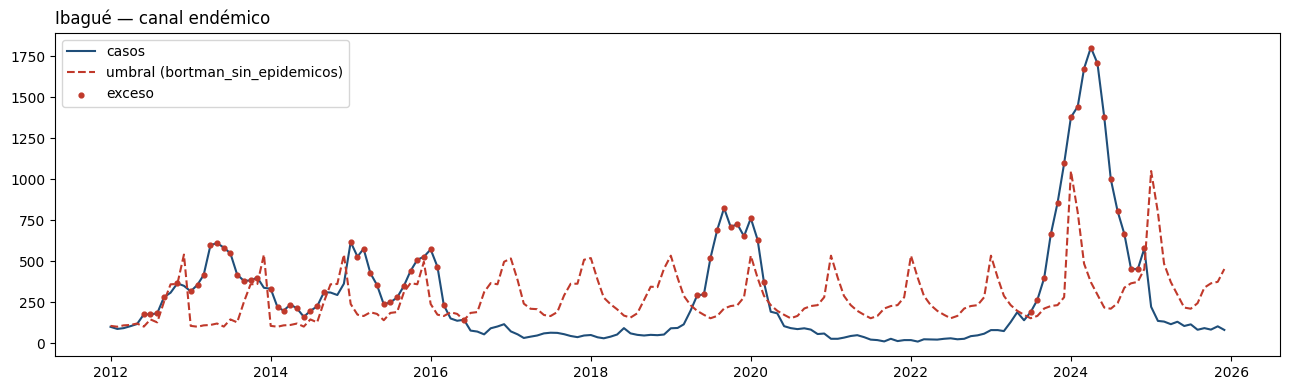

In [ ]:
fig, ax = plt.subplots(figsize=(13, 4))
d = df.dropna(subset=['umbral'])
ax.plot(d.index, d['valor'], label=UNIDAD, color='#1f4e79')
ax.plot(d.index, d['umbral'], label=f'umbral ({METODO_CANAL})', color='#c0392b', ls='--')
ax.scatter(d.index[d['exceso'] == 1], d.loc[d['exceso'] == 1, 'valor'], color='#c0392b', s=12, zorder=3, label='exceso')
ax.set_title('Ibagué — canal endémico', loc='left'); ax.legend(); plt.tight_layout(); plt.show()

## 7. Nivel 2: serie mensual
Una fila por mes con todo lo que se mide ese mes. `exceso` se calcula aquí porque es una propiedad del mes; en el nivel 3 solo se trae la del mes objetivo.

In [ ]:
nivel2 = pd.DataFrame({
    'municipio': MUNICIPIO,
    'casos':     df['casos'],
    'lluvia_mm': df['lluvia_mm'],
    'temp_c':    df['temp_media'],
    'oni':       df['oni'],
    'umbral':    df['umbral'],
    'exceso':    df['exceso'],
})
nivel2['pandemia'] = nivel2.index.to_series().between(*PANDEMIA).astype(int)
nivel2.index.name = 'mes'
nivel2.dropna(subset=['lluvia_mm']).head()

,municipio,casos,lluvia_mm,temp_c,oni,umbral,exceso,pandemia
mes,,,,,,,,
2010-01-01,Ibagué,654,66.544993,18.947253,1.50,NaN,<NA>,0
2010-02-01,Ibagué,1165,67.881139,19.594161,1.47,NaN,<NA>,0
2010-03-01,Ibagué,1390,168.772812,19.291128,1.21,NaN,<NA>,0
2010-04-01,Ibagué,1056,537.779353,17.883565,0.88,NaN,<NA>,0
2010-05-01,Ibagué,697,344.159899,17.726619,0.38,NaN,<NA>,0


## 8. Nivel 3: tabla de modelado
Cada fila es un ejemplo: para predecir el mes **t** se usan los meses **t-5 a t-2** (con `HORIZONTE = 2` y `HISTORIA = 4`). Los casos del mes objetivo **no** son predictor; solo se usan para la etiqueta.

16 predictores:

| Grupo | Columnas |
|---|---|
| Lluvia | `P_t-5` … `P_t-2` |
| Temperatura | `T_t-5` … `T_t-2` |
| Casos (log) | `logC_t-5` … `logC_t-2` |
| Contexto | `mes_sin`, `mes_cos` (del mes objetivo), `oni_t-2`, `exceso_t-2` |

Los casos van en log(casos + 1) porque la serie va de ~10 a más de 1.000 por mes. La estacionalidad es necesaria porque el umbral del canal cambia según el mes.

In [ ]:
lags = range(HORIZONTE, HORIZONTE + HISTORIA)            # 2, 3, 4, 5
tabla = pd.DataFrame(index=nivel2.index)                 # índice = mes objetivo t
tabla['municipio'] = MUNICIPIO
tabla['mes_objetivo'] = tabla.index
for k in sorted(lags, reverse=True):
    tabla[f'P_t-{k}'] = nivel2['lluvia_mm'].shift(k)
for k in sorted(lags, reverse=True):
    tabla[f'T_t-{k}'] = nivel2['temp_c'].shift(k)
for k in sorted(lags, reverse=True):
    tabla[f'logC_t-{k}'] = np.log1p(nivel2['casos'].shift(k))
tabla['mes_sin'] = np.sin(2 * np.pi * tabla.index.month / 12)
tabla['mes_cos'] = np.cos(2 * np.pi * tabla.index.month / 12)
tabla[f'oni_t-{HORIZONTE}'] = nivel2['oni'].shift(HORIZONTE)
tabla[f'exceso_t-{HORIZONTE}'] = nivel2['exceso'].shift(HORIZONTE)
tabla['pandemia'] = nivel2['pandemia']
tabla['exceso'] = nivel2['exceso']

PREDICTORES = [c for c in tabla.columns if c not in ('municipio', 'mes_objetivo', 'pandemia', 'exceso')]
print(len(PREDICTORES), 'predictores:', PREDICTORES)

16 predictores: ['P_t-5', 'P_t-4', 'P_t-3', 'P_t-2', 'T_t-5', 'T_t-4', 'T_t-3', 'T_t-2', 'logC_t-5', 'logC_t-4', 'logC_t-3', 'logC_t-2', 'mes_sin', 'mes_cos', 'oni_t-2', 'exceso_t-2']


## 9. Partición temporal
Por **año del mes objetivo**, en bloques consecutivos (nunca aleatoria). Las filas empiezan en 2012 porque el canal necesita 5 años previos.

La validación es 2019–2022 y no solo 2021–2022 porque esos dos años no tienen ningún mes en exceso: sin positivos no se puede medir sensibilidad ni afinar nada. Flujo: ajustar hiperparámetros con train → val, reentrenar con train + val y evaluar **una sola vez** en test (2023–2025, incluye la epidemia de 2024).

Con `EXCLUIR_PANDEMIA = True` se sacan los meses objetivo de la pandemia (los meses siguen sirviendo como rezago). Reportar las dos versiones.

In [ ]:
anio = tabla.index.year
tabla['split'] = None
for nombre, (a0, a1) in PARTICION.items():
    tabla.loc[(anio >= a0) & (anio <= a1), 'split'] = nombre

antes = len(tabla)
tabla = tabla.dropna(subset=PREDICTORES + ['exceso', 'split'])
if EXCLUIR_PANDEMIA:
    tabla = tabla[tabla['pandemia'] == 0]
tabla['exceso'] = tabla['exceso'].astype(int)
tabla[f'exceso_t-{HORIZONTE}'] = tabla[f'exceso_t-{HORIZONTE}'].astype(int)
print(f'Filas útiles: {len(tabla)} de {antes} | excluir pandemia: {EXCLUIR_PANDEMIA}')
tabla.groupby('split', sort=False)['exceso'].agg(meses='size', excesos='sum', proporcion='mean').round(2)

Filas útiles: 166 de 228 | excluir pandemia: False


,meses,excesos,proporcion
split,,,
train,82,41,0.50
val,48,11,0.23
test,36,18,0.50


## 10. Línea base de referencia
**Persistencia:** el mes t estará igual que el último mes observado (t-2). Cualquier modelo que no le gane a esto no aporta. Métricas para clases desbalanceadas: sensibilidad (recall), precisión, F1 y PR-AUC.

`recall_inicios` mide cuántos **inicios de brote** (pasar de normal a exceso) se anticipan. La persistencia nunca acierta uno, por construcción: ahí es donde un modelo con clima tiene que demostrar su valor. Usen esta misma función `evaluar` en sus modelos para que los resultados sean comparables.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score

ULTIMO = f'exceso_t-{HORIZONTE}'

def evaluar(g, pred, prob=None):
    y, pred = g['exceso'], pd.Series(np.asarray(pred), index=g.index)
    inicio = (y == 1) & (g[ULTIMO] == 0)
    return {'recall': recall_score(y, pred, zero_division=0),
            'recall_inicios': pred[inicio].mean() if inicio.any() else np.nan,
            'n_inicios': int(inicio.sum()),
            'precision': precision_score(y, pred, zero_division=0),
            'f1': f1_score(y, pred, zero_division=0),
            'pr_auc': average_precision_score(y, prob) if prob is not None else np.nan}

pd.DataFrame({s: evaluar(g, g[ULTIMO]) for s, g in tabla.groupby('split', sort=False)}).T.round(2)

,recall,recall_inicios,n_inicios,precision,f1,pr_auc
train,0.83,0.0,7.0,0.83,0.83,NaN
val,0.82,0.0,2.0,0.82,0.82,NaN
test,0.89,0.0,2.0,0.89,0.89,NaN


## 11. Exportar

In [ ]:
sufijo = '_sin_pandemia' if EXCLUIR_PANDEMIA else ''
nivel2.to_csv(f'{SALIDA}/serie_nivel2_{COD_MUN}.csv')
tabla.to_csv(f'{SALIDA}/tabla_modelado_{COD_MUN}{sufijo}.csv', index=False)
print('Guardado en', SALIDA)

Guardado en /content/drive/MyDrive/Datos/dengue/procesado


## Cómo cargarla para entrenar
```python
tabla = pd.read_csv('/content/drive/MyDrive/Datos/dengue/procesado/tabla_modelado_73001.csv', parse_dates=['mes_objetivo'])
PREDICTORES = [c for c in tabla.columns if c not in ('municipio', 'mes_objetivo', 'pandemia', 'exceso', 'split')]
train, val, test = (tabla[tabla.split == s] for s in ('train', 'val', 'test'))
X_train, y_train = train[PREDICTORES], train['exceso']
```